In [1]:
import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

Python: 3.13.16
PyTorch: 2.11.0+cpu
GPU disponible: False


In [2]:

# PASO 2: CONFIGURACIÓN DEL EXPERIMENTO

import random
import json
import platform
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
from pathlib import Path

# 1. Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Detectar el dispositivo disponible
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# 3. Hiperparámetros
LEARNING_RATE = 0.01
BATCH_SIZE = 64
EPOCHS = 30
N_SAMPLES = 2400
N_FEATURES = 10
N_CLASSES = 3

# 4. Crear un dataset sintético reproducible
generator = torch.Generator().manual_seed(SEED)

centers = torch.zeros(N_CLASSES, N_FEATURES)
centers[0] = -2.0
centers[1] = 0.0
centers[2] = 2.0

labels = torch.randint(
    low=0,
    high=N_CLASSES,
    size=(N_SAMPLES,),
    generator=generator
)

features = centers[labels] + 0.9 * torch.randn(
    N_SAMPLES, N_FEATURES, generator=generator
)

# Mezclar los ejemplos
permutation = torch.randperm(N_SAMPLES, generator=generator)
features = features[permutation]
labels = labels[permutation]

# 5. Separar entrenamiento (70%), validación (15%) y prueba (15%)
n_train = int(0.70 * N_SAMPLES)
n_val = int(0.15 * N_SAMPLES)

X_train = features[:n_train]
y_train = labels[:n_train]

X_val = features[n_train:n_train + n_val]
y_val = labels[n_train:n_train + n_val]

X_test = features[n_train + n_val:]
y_test = labels[n_train + n_val:]

# 6. Crear los DataLoaders
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

# 7. Definir el clasificador base
class BaseClassifier(nn.Module):
    def __init__(self, input_features, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)

model = BaseClassifier(N_FEATURES, N_CLASSES).to(device)

# 8. Función de pérdida y optimizador Adam
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(), lr=LEARNING_RATE
)

# 9. Preparar el registro de métricas
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

# 10. Mostrar la configuración
print("CONFIGURACIÓN COMPLETADA")
print("------------------------")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("Ejemplos de entrenamiento:", len(train_dataset))
print("Ejemplos de validación:", len(val_dataset))
print("Ejemplos de prueba:", len(test_dataset))
print("\nArquitectura del modelo:")
print(model)
print("\nLearning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Épocas:", EPOCHS)


CONFIGURACIÓN COMPLETADA
------------------------
Python: 3.13.16
PyTorch: 2.11.0+cpu
Dispositivo: cpu
Ejemplos de entrenamiento: 1680
Ejemplos de validación: 360
Ejemplos de prueba: 360

Arquitectura del modelo:
BaseClassifier(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
)

Learning rate: 0.01
Batch size: 64
Épocas: 30


In [3]:

# PASO 3: ENTRENAMIENTO Y VALIDACIÓN

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += batch_size

    return total_loss / total, correct / total


for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    seen = 0

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device)

        # Reiniciar los gradientes
        optimizer.zero_grad()

        # Obtener predicciones
        logits = model(features)

        # Calcular la pérdida
        loss = criterion(logits, labels)

        # Retropropagación
        loss.backward()

        # Actualizar parámetros con Adam
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        seen += batch_size

    train_loss = running_loss / seen

    # Validar sin actualizar los parámetros
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    # Guardar métricas de cada época
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Época {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%}"
    )

print("\n¡Entrenamiento finalizado correctamente!")


Época 01/30 | Train Loss: 0.4766 | Val Loss: 0.2229 | Val Accuracy: 96.11%
Época 02/30 | Train Loss: 0.1156 | Val Loss: 0.0449 | Val Accuracy: 99.72%
Época 03/30 | Train Loss: 0.0242 | Val Loss: 0.0151 | Val Accuracy: 99.72%
Época 04/30 | Train Loss: 0.0091 | Val Loss: 0.0090 | Val Accuracy: 100.00%
Época 05/30 | Train Loss: 0.0055 | Val Loss: 0.0075 | Val Accuracy: 100.00%
Época 06/30 | Train Loss: 0.0040 | Val Loss: 0.0065 | Val Accuracy: 100.00%
Época 07/30 | Train Loss: 0.0032 | Val Loss: 0.0057 | Val Accuracy: 100.00%
Época 08/30 | Train Loss: 0.0025 | Val Loss: 0.0049 | Val Accuracy: 100.00%
Época 09/30 | Train Loss: 0.0020 | Val Loss: 0.0047 | Val Accuracy: 100.00%
Época 10/30 | Train Loss: 0.0018 | Val Loss: 0.0045 | Val Accuracy: 100.00%
Época 11/30 | Train Loss: 0.0015 | Val Loss: 0.0042 | Val Accuracy: 99.72%
Época 12/30 | Train Loss: 0.0013 | Val Loss: 0.0042 | Val Accuracy: 100.00%
Época 13/30 | Train Loss: 0.0011 | Val Loss: 0.0040 | Val Accuracy: 100.00%
Época 14/30 | Tr

RESULTADOS FINALES
------------------
Test Loss: 0.0007
Test Accuracy: 100.00%


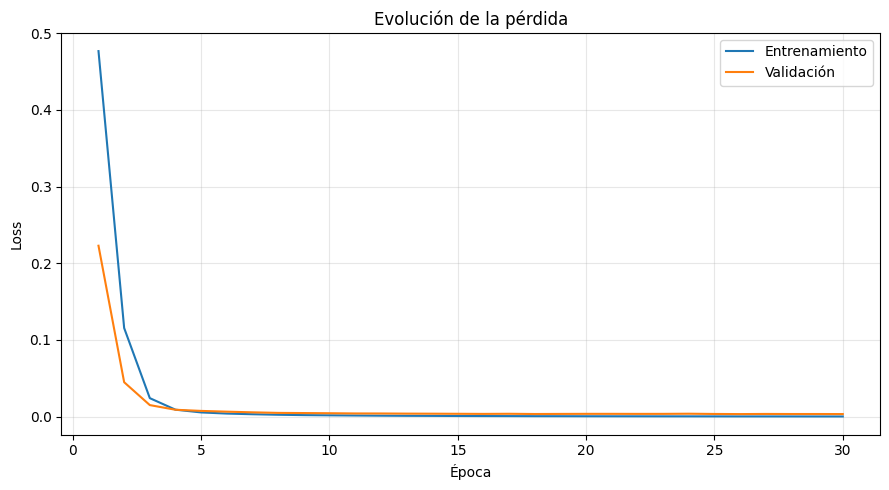

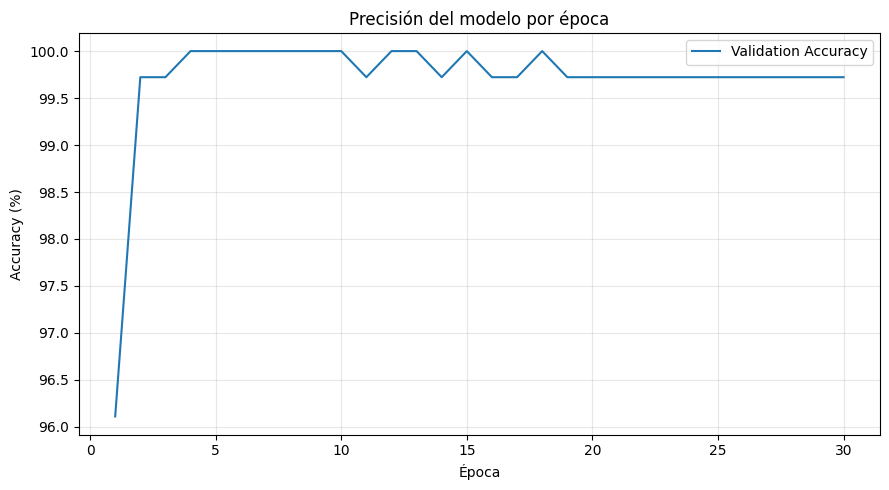


Archivos generados:
- loss_curve.png
- accuracy_curve.png
- metrics.json
- model_weights.pth


In [4]:

# PASO 4: EVALUACIÓN FINAL Y VISUALIZACIÓN DE RESULTADOS

import matplotlib.pyplot as plt
import json
from pathlib import Path

# 1. Evaluar el modelo con el conjunto de prueba
test_loss, test_accuracy = evaluate(
    model, test_loader, criterion, device
)

print("RESULTADOS FINALES")
print("------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

# 2. Graficar la pérdida de entrenamiento y validación
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, history["train_loss"], label="Entrenamiento")
plt.plot(epochs_range, history["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolución de la pérdida")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

# 3. Graficar Accuracy de validación
plt.figure(figsize=(9, 5))
plt.plot(
    epochs_range,
    [x * 100 for x in history["val_accuracy"]],
    label="Validation Accuracy"
)
plt.xlabel("Época")
plt.ylabel("Accuracy (%)")
plt.title("Precisión del modelo por época")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=150)
plt.show()

# 4. Guardar las métricas en un archivo JSON
results = {
    "python_version": __import__("platform").python_version(),
    "pytorch_version": torch.__version__,
    "device": str(device),
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "train_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "test_samples": len(test_dataset),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "history": history
}

with open("metrics.json", "w", encoding="utf-8") as file:
    json.dump(results, file, indent=2, ensure_ascii=False)

# 5. Guardar los parámetros entrenados del modelo
torch.save(model.state_dict(), "model_weights.pth")

print("\nArchivos generados:")
print("- loss_curve.png")
print("- accuracy_curve.png")
print("- metrics.json")
print("- model_weights.pth")


In [5]:

# PASO 5: EMPAQUETAR LOS RESULTADOS

import zipfile
from pathlib import Path

files_to_save = [
    "loss_curve.png",
    "accuracy_curve.png",
    "metrics.json",
    "model_weights.pth"
]

with zipfile.ZipFile(
    "resultados_entrenamiento.zip", "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:
    for filename in files_to_save:
        if Path(filename).exists():
            zip_file.write(filename)

print("Paquete de resultados creado correctamente.")


Paquete de resultados creado correctamente.


In [6]:

from google.colab import files
files.download("resultados_entrenamiento.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>